In [1]:
%load_ext autoreload
%autoreload 2

# CICE + MOM6: real global restart, end to end

Same wiring as `cice_with_obcs.ipynb` (synthetic `reference_ice`), swapped to a real global CICE restart: `cice_product_name="cice_restart"`, `cice_function_args={"restart_path": ..., "grid_path": ...}`. MOM6's own IC/OBC still use the fast `reference_ocean` product.

The restart file itself carries no grid of its own (just raw ni/nj/ncat state on the model's native tripole index space), so `cice_restart` also needs the matching **CICE tripole grid file** to locate the bounding box's (nj, ni) window (`find_cice_index_window` in `raw_data_access/datasets/cice_output.py`). This restart's case name encodes its ocean grid resolution tag (`..._t233_...` -> tripole `tx2_3v3`); its `(ni, nj)` = (540, 480) dims match `/glade/campaign/cesm/community/omwg/grids/tx2_3v3_grid.nc` exactly, which is what's used below. For a restart from a different resolution, find the matching grid file the same way -- by resolution tag in the case name, or by matching `(ni, nj)` dims against `/glade/campaign/cesm/community/omwg/grids/`.

## Step 0: Paths and imports

Follows the "Fast CrocoDash Case Setup" pattern from the repo's `CLAUDE.md`.

In [12]:
from pathlib import Path

from CrocoDash.grid import Grid
from CrocoDash.topo import Topo
from CrocoDash.vgrid import VGrid
from CrocoDash.case import Case

CESMROOT = Path("/glade/u/home/manishrv/work/installs/full_regional_cesm").expanduser()
CASENAME = "alaska2"
CASEROOT = (Path("~/croc_cases") / CASENAME).expanduser()
INPUTDIR = (Path("~/scratch/croc_input") / CASENAME).expanduser()

RESTART_PATH = "/glade/u/home/dbailey/b.e30_alpha09b.B1850C_MTso.ne30_t233_wgx3.360.cice.r.0201-01-01-00000.nc"
GRID_PATH = "/glade/campaign/cesm/community/omwg/grids/tx2_3v3_grid.nc"

print(CESMROOT)
print(CASEROOT)
print(INPUTDIR)

/glade/u/home/manishrv/work/installs/full_regional_cesm
/glade/u/home/manishrv/croc_cases/alaska2
/glade/u/home/manishrv/scratch/croc_input/alaska2


## Step 1: Grid, topography, vertical grid

Same Bering Sea domain as the synthetic-data demo -- high enough latitude that this restart's January sea ice actually reaches it.

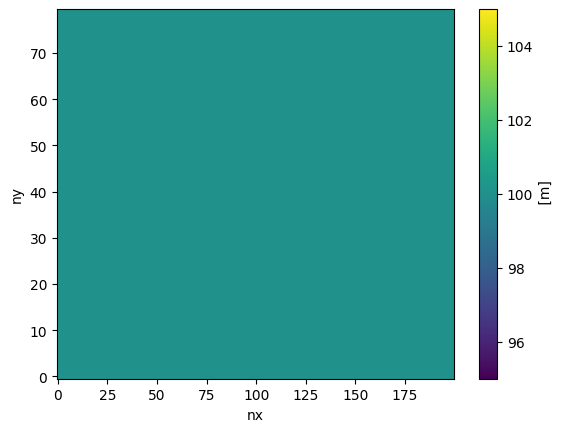

In [7]:
bathymetry_path = "/glade/campaign/cgd/oce/projects/CROCODILE/workshops/2025/CrocoDash/data/gebco_2022/GEBCO_2024_coarse_x4.nc"

grid = Grid(
  resolution = 0.25, # in degrees
  xstart = 170.0, # min longitude in [0, 360]
  lenx = 50.0, # longitude extent in degrees
  ystart = 60.0, # min latitude in [-90, 90]
  leny = 20.0, # latitude extent in degrees
  name = CASENAME,
)

topo = Topo(grid, min_depth=10.0, git=False)

topo.set_flat(100)

topo.depth.plot()


In [8]:
vgrid  = VGrid.hyperbolic(
    nk = 75, # number of vertical levels
    depth = topo.max_depth,
    ratio=20.0 # target ratio of top to bottom layer thicknesses
)

## Step 2: Create the case

Same `CICE` swap as the synthetic-data demo.

In [13]:
case = Case(
    cesmroot=CESMROOT,
    caseroot=CASEROOT,
    inputdir=INPUTDIR,
    compset="1850_DATM%NYF_SLND_CICE_MOM6%REGIONAL_SROF_SGLC_SWAV",
    ocn_grid=grid,
    ocn_topo=topo,
    ocn_vgrid=vgrid,
    atm_grid_name="T62",
    machine="derecho",
    project="P93300065",
    override=True,
)
print("CICE in compset:", case.cice_in_compset)

INFO:	initialize:Initializing the visualCaseGen system...


INFO:  csp_solver:CspSolver initialized.


Creating case...

Running the create_newcase tool with the following command:

/glade/u/home/manishrv/work/installs/full_regional_cesm/cime/scripts/create_newcase --compset 1850_DATM%NYF_SLND_CICE_MOM6%REGIONAL_SROF_SGLC_SWAV --res USER_RES --case /glade/u/home/manishrv/croc_cases/alaska2 --machine derecho --run-unsupported --project P93300065 --non-local 

The create_newcase command was successful.

• Updating case xml variables to include newly generated ocean grid "alaska2" with the following properties:
 nx: 200, ny: 80. ocean mesh: /glade/u/home/manishrv/scratch/croc_input/alaska2/ocnice/ESMF_mesh_alaska2_f7cc4a.nc.

./xmlchange OCN_NX=200 --non-local

./xmlchange OCN_NY=80 --non-local

./xmlchange OCN_DOMAIN_MESH=/glade/u/home/manishrv/scratch/croc_input/alaska2/ocnice/ESMF_mesh_alaska2_f7cc4a.nc --non-local

./xmlchange ICE_NX=200 --non-local

./xmlchange ICE_NY=80 --non-local

./xmlchange ICE_DOMAIN_MESH=/glade/u/home/manishrv/scratch/croc_input/alaska2/ocnice/ESMF_mesh_alaska2

INFO:	stage:SUCCESS: All stages are complete.


Case created successfully at /glade/u/home/manishrv/croc_cases/alaska2.

To further customize, build, and run the case, navigate to the case directory in your terminal. To create another case, restart the notebook.

./xmlchange MOM6_MEMORY_MODE=dynamic_symmetric --non-local

The following additional configuration options are required to run and must be provided with any listed arguments in configure_forcings:
  - CICE: no arguments
  - conditions: boundaries, product_name, function_name, compset
CICE in compset: True


## Step 3: Configure + process forcings

`cice_function_args` carries the real restart+grid paths through to `get_cice_restart_subset` -- everything else about the call is identical to the synthetic-data demo.

In [ ]:
case.configure_forcings(
    date_range=["2020-01-01 00:00:00", "2021-01-03 00:00:00"],
    product_name = "cesm_pop_output",
    function_name="get_mom6_output_data",
    cice_product_name="cice_restart",
    cice_function_name="get_cice_restart_subset",
    cice_function_args={"restart_path": RESTART_PATH, "grid_path": GRID_PATH},
    n_halo_cells=1,
)

INFO:CrocoDash.forcing.base:[SKIP] BGC incompatible with compset
INFO:CrocoDash.forcing.base:[SKIP] BGCIC incompatible with compset
INFO:CrocoDash.forcing.base:[SKIP] BGCIronForcing incompatible with compset
INFO:CrocoDash.forcing.base:[SKIP] BGCRiverNutrients incompatible with compset
INFO:CrocoDash.forcing.base:[SKIP] Chl missing args: ['chl_processed_filepath']
INFO:CrocoDash.forcing.base:[REQUIRED] Activating CICE
INFO:CrocoDash.forcing.base:[REQUIRED] Activating conditions
INFO:CrocoDash.forcing.base:[SKIP] Runoff incompatible with compset
INFO:CrocoDash.forcing.base:[SKIP] tides missing args: ['tpxo_elevation_filepath', 'tpxo_velocity_filepath', 'tidal_constituents']
INFO:CrocoDash.forcing.base:Configuring CICE
INFO:CrocoDash.forcing.base:Configuring conditions


Adding parameter changes to user_nl_cice:

  ice_ic = 'default'

Adding parameter changes to user_nl_cice:

  ns_boundary_type = 'zero_gradient'

Adding parameter changes to user_nl_cice:

  ew_boundary_type = 'zero_gradient'

Adding parameter changes to user_nl_cice:

  close_boundaries = .false.

Adding parameter changes to user_nl_cice:

  advect = 'upwind'

Adding parameter changes to user_nl_cice:

  restore_ice = .true.

Adding parameter changes to user_nl_cice:

  trestore = 90

Adding parameter changes to user_nl_mom:

  ! Initial conditions
  INIT_LAYERS_FROM_Z_FILE = True
  Z_INIT_ALE_REMAPPING = True
  TEMP_SALT_INIT_VERTICAL_REMAP_ONLY = True
  DEPRESS_INITIAL_SURFACE = True
  VELOCITY_CONFIG = file
  TEMP_SALT_Z_INIT_FILE = init_tracers.nc
  SURFACE_HEIGHT_IC_FILE = init_eta.nc
  VELOCITY_FILE = init_vel.nc
  Z_INIT_FILE_PTEMP_VAR = temp
  Z_INIT_FILE_SALT_VAR = salt
  SURFACE_HEIGHT_IC_VAR = eta_t
  U_IC_VAR = u
  V_IC_VAR = v

  ! Open boundary conditions
  OBC_NUMBER_OF

In [16]:
case.process_forcings()

INFO:CrocoDash.forcing.ic:[CESM_MOM_OUTPUT.get_mom6_output_data] Usage: Point dataset_path at any directory of MOM6 output NetCDF files (a parent run's history dir, or diag_table-extracted region slices). Narrow which files are read with file_glob, e.g. '*.ocean_month_z*.nc' for full history, or '<case_prefix>.<region_name>*.nc' for a nesting cross-section.


FileNotFoundError: Provided dataset path None does not exist. Please provide a valid path through the function arguments

## Case is set up

MOM6's own IC/OBC are in `case.inputdir / "ocean"` and CICE's `cice_forcing.nc` (covering the domain plus its 2-cell halo) is in `case.inputdir / "sea_ice"`.

In [ ]:
print("caseroot:", case.caseroot)
print("inputdir:", case.inputdir)
print("supergrid_path:", case.supergrid_path)

## Inspect CICE's forcing file

Unlike `reference_ice`'s synthetic linear taper, this is the real global restart's January ice state, index-subset to the domain+halo window and regridded onto it -- real Bering Sea concentration/thickness/temperature patterns, not a smooth analytic gradient.

In [ ]:
import xarray as xr

cice_ds = xr.open_dataset(case.inputdir / "sea_ice" / "cice_forcing.nc")
print("dims:", dict(cice_ds.sizes))
print("domain (T-cells):", grid.tlon.shape, "-> with halo:", (cice_ds.sizes["ny"], cice_ds.sizes["nx"]))
print("total sea ice area (aicen sum):", float(cice_ds["aicen"].sum()))

## Plot real ice concentration on the expanded grid

Summed across the 5 thickness categories -- should show real spatial structure (a concentration front, not a uniform taper) since this is an actual January CICE state, not a synthetic gradient.

In [ ]:
import matplotlib.pyplot as plt

aice_total = cice_ds["aicen"].sum(dim="ncat")
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.pcolormesh(aice_total.values, cmap="Blues", vmin=0, vmax=1)
ax.set_title("Total sea ice concentration, day 1 (real tx2_3v3 restart)")
ax.set_xlabel("nx (domain + halo)")
ax.set_ylabel("ny (domain + halo)")
fig.colorbar(im, ax=ax, label="aice")
plt.show()